# <span style = 'color:Orange'>**Softmax Regression**</span>


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score,confusion_matrix

In [2]:
df = pd.read_csv('drug_class.csv')
df.head()

,Age,Gender,BloodPressure,Cholestrol,Na_to_K,Class
0,23,M,LOW,HIGH,7.301033,drugC
1,69,M,LOW,HIGH,15.478000,drugY
2,74,M,HIGH,HIGH,9.516477,drugB
3,60,M,HIGH,NORMAL,8.742942,drugB
4,39,F,NORMAL,NORMAL,9.715872,drugX


In [3]:
# age -> scaler
# Na_to_K -> scaler

# BloodPRessure -> ordinalEcnoding
# Cholestrol -> ordinal Encoding

# Gender -> oneHotEncoding
print(df['Cholestrol'].unique())
print(df['BloodPressure'].unique())

['HIGH' 'NORMAL']
['LOW' 'HIGH' 'NORMAL']


In [4]:
scaling = ['Age','Na_to_K']
ordinal_bp = ['BloodPressure']
ordinal_chol = ['Cholestrol']
onehot = ['Gender']

feature_cols = scaling + ordinal_bp + ordinal_chol + onehot

x = df[feature_cols]
y = df['Class']

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [5]:
# individial pipeline

scaling_pipeline = Pipeline(steps = [
    ('scale',StandardScaler())
])

ordinal_bp_pipeline = Pipeline(steps = [
    ('encode',OrdinalEncoder(categories=[['LOW','NORMAL',"HIGH"]]))
])

ordinal_chol_pipeline = Pipeline(steps = [
    ('encode',OrdinalEncoder(categories=[['NORMAL',"HIGH"]]))
])

onehot_pipeline = Pipeline(steps = [
    ('encode',OneHotEncoder(handle_unknown='ignore'))
])

In [6]:
# preprocessor pipeline
preporcessor_pipeline = ColumnTransformer(transformers=[
    ('Scaled Pipeline', scaling_pipeline, scaling),
    ('Ordinal BP Pipeline', ordinal_bp_pipeline, ordinal_bp),
    ('Ordinal Chol Pipeline', ordinal_chol_pipeline, ordinal_chol),
    ('Onehot Pipeline', onehot_pipeline, onehot)
])

preporcessor_pipeline

ColumnTransformer(transformers=[('Scaled Pipeline',
                                 Pipeline(steps=[('scale', StandardScaler())]),
                                 ['Age', 'Na_to_K']),
                                ('Ordinal BP Pipeline',
                                 Pipeline(steps=[('encode',
                                                  OrdinalEncoder(categories=[['LOW',
                                                                              'NORMAL',
                                                                              'HIGH']]))]),
                                 ['BloodPressure']),
                                ('Ordinal Chol Pipeline',
                                 Pipeline(steps=[('encode',
                                                  OrdinalEncoder(categories=[['NORMAL',
                                                                              'HIGH']]))]),
                                 ['Cholestrol']),
                                ('Onehot Pipeline',
                                 Pipeline(steps=[('encode',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Gender'])])

In [7]:
# model train
model = Pipeline(
    steps = [
        ('preprocess',preporcessor_pipeline),
        ('classify',LogisticRegression(multi_class="multinomial"))
    ]
)

In [8]:
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

In [9]:
# hyperparameter tuning

params_grid = {
    'classify__C': [0.01, 0.1, 1, 10, 100],
    'classify__solver': ['lbfgs', 'newton-cg', 'sag', 'saga'],
    'classify__max_iter': [1000, 2000],
    'classify__class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    estimator=model,
    param_grid=params_grid,
    cv = 5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(x_train,y_train)

print('best model :',grid.best_estimator_)
print('best parameters :',grid.best_params_)
print('best score:',grid.best_score_)

/Users/lucifer/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/lucifer/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/lucifer/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/lucifer/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logisti

best model : Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('Scaled Pipeline',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['Age', 'Na_to_K']),
                                                 ('Ordinal BP Pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['LOW',
                                                                                               'NORMAL',
                                                                                               'HIGH']]))]),
                                                  ['BloodPressure']),
                                                 ('Ordinal Chol Pipeline',
                                         

/Users/lucifer/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/lucifer/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/lucifer/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/lucifer/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logisti

In [10]:
sft_best = grid.best_estimator_
sft_best

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('Scaled Pipeline',
                                                  Pipeline(steps=[('scale',
                                                                   StandardScaler())]),
                                                  ['Age', 'Na_to_K']),
                                                 ('Ordinal BP Pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['LOW',
                                                                                               'NORMAL',
                                                                                               'HIGH']]))]),
                                                  ['BloodPressure']),
                                                 ('Ordinal Chol Pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OrdinalEncoder(categories=[['NORMAL',
                                                                                               'HIGH']]))]),
                                                  ['Cholestrol']),
                                                 ('Onehot Pipeline',
                                                  Pipeline(steps=[('encode',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Gender'])])),
                ('classify',
                 LogisticRegression(C=100, max_iter=1000,
                                    multi_class='multinomial'))])

accuracy score:  0.989010989010989



<Axes: >

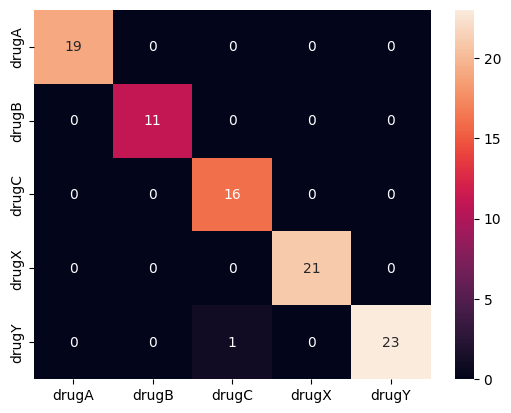

In [11]:
y_pred = sft_best.predict(x_test)

print('accuracy score: ',accuracy_score(y_test, y_pred))

print()
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, xticklabels=sft_best.classes_, yticklabels=sft_best.classes_)

In [13]:
age = int(input("Enter Age: "))
na_to_k = float(input("Enter Na_to_K ratio: "))
bp = input("Enter BloodPressure (LOW/NORMAL/HIGH): ").upper()
chol = input("Enter Cholestrol (NORMAL/HIGH): ").upper()
gender = input("Enter Gender (M/F): ").upper()

user = pd.DataFrame({
    'Age': [age],
    'Na_to_K': [na_to_k],
    'BloodPressure': [bp],
    'Cholestrol': [chol],
    'Gender': [gender]
})

prediction = sft_best.predict(user)

print("\nPredicted Drug Class:", prediction[0])


Predicted Drug Class: drugX
